# Lab 05 · A batch we can restart and explain

Automated Workflows in Satellite Image Processing · 5 November 2026

Lab 4 gave us one configured NDVI job. Lecture 5 asked whether its results were available, useful and explainable. Now we will run six requests and see what happens when one of them cannot finish.

By the end, you should be able to point to the expected work, explain an incomplete batch, recover it without losing history, and produce a report that another person can investigate.

The main exercise uses actual Sentinel-2 Collection 1 subsets from three dates near Kraków. Each date supplies two AOIs. The preserved inputs stay unchanged. Cloud screening comes later.

Core work: three new database tables, three logical repairs, two failure investigations, and a short decision. Allow about two hours. Coordinator interruption, missing outputs and the live acquisition route are extensions.

## 1. Open the package and inspect the evidence

Run the notebook from the Lab05 directory. Keep the supplied Python files beside it.

In [1]:
from pathlib import Path
from contextlib import closing, redirect_stdout
from io import StringIO
from unittest.mock import patch
import json, sqlite3, sys
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import lab05_cli as app
import check_lab05 as checks
import batch_plan

ROOT = Path.cwd().resolve()
assert (ROOT / 'lab05_cli.py').is_file(), 'Open the notebook from Lab05.'

def cli(*args, expected=(0,)):
    output = StringIO()
    with patch.object(sys, 'argv', ['lab05_cli.py', *map(str, args)]), redirect_stdout(output):
        code = app.main()
    assert code in expected, (code, output.getvalue()[-2500:])
    return json.loads(output.getvalue())

def check(group='all'):
    for name in (checks.CHECKS if group == 'all' else [group]):
        checks.CHECKS[name]()
        print('PASS', name)
    return True

def query(manifest_path, sql, params=()):
    manifest = batch_plan.load(manifest_path)
    with closing(sqlite3.connect(manifest['_database'])) as connection:
        connection.row_factory = sqlite3.Row
        connection.execute('PRAGMA foreign_keys=ON')
        return [dict(row) for row in connection.execute(sql, params)]

print('Python', sys.version.split()[0], 'Rasterio', rasterio.__version__)
fixture = json.loads((ROOT / 'fixtures/manifest.json').read_text())
print('Endpoint:', fixture['endpoint'], 'Collection:', fixture['collection'])
print('Requests:', len(fixture['members']))

Python 3.13.7 Rasterio 1.5.2
Endpoint: https://earth-search.aws.element84.com/v1 Collection: sentinel-2-c1-l2a
Requests: 6


In [2]:
first_member = fixture['members'][0]
for role, entry in first_member['bands'].items():
    with rasterio.open(ROOT / 'fixtures' / entry['file']) as source:
        raw = source.read(1, masked=True)
        print(role, first_member['member_id'], source.shape, source.crs, source.scales, source.offsets, entry['sha256'])
        print('DN median:', float(np.ma.median(raw)))
print('Source transfer bytes:', sum(t['network_bytes'] for t in fixture['transfers']))

red S2A_T34UDA_20250604T094637_L2A-river (227, 219) EPSG:32634 (0.0001,) (-0.1,) ef3ca867df64c8b756ddd817d1ec25c6722f6e88a734863a63a95a9986abf684
DN median: 1778.0
nir S2A_T34UDA_20250604T094637_L2A-river (227, 219) EPSG:32634 (0.0001,) (-0.1,) e30bbf323834e7602031458e2b00f3d4b5e2ac06cd22a7967acf2032c78ec25c
DN median: 3441.0
Source transfer bytes: 12582918


Name one property a checksum establishes and one scientific question it cannot answer. Explain why six requests here represent three dates rather than six independent acquisitions.

Your explanation:

*Write here.*

1. A checksum establishes byte identity, but cannot establish cloud suitability.
2. Each of the three acquisitions supplies two AOIs, giving six requests.

## 2. Design the new tables

Read `SCHEMA_CONTRACT.md`. Write all three tables in `student_batch_schema.sql`. The earlier acquisition and processing schemas are completed in `support/`.

Before writing SQL, sketch the links between a batch, its expected members, their requests, attempts and observations. Decide which records must exist when we know what we want but no calculation has started.

A member's planned request ID exists before its optional request foreign key can be filled. Explain why those are separate fields. Then run the schema check.

In [3]:
schema_ok = check('schema')

PASS schema


Your explanation:

*Write here.*

A batch contains expected members before execution; members link planned requests to attempts and append-only observations.
The planned ID identifies intended work, while the nullable request foreign key is filled only after registration.

## 3. Repair the coordination logic

The functions in `batch_repairs.py` execute, but the supplied versions make incorrect decisions. Read their contracts and repair them.

`classify_member` needs to distinguish blocked inputs, unresolved execution, verified completion and a permitted new attempt. A finished result may remain usable after its inputs move. An unresolved active execution needs attention even when an older result exists. The attempt budget does not reset when the coordinator restarts.

`verify_result` must reject evidence for another request, mismatching bytes, or missing verification. The adapter does the actual catalogue queries, hashing and raster inspection.

`summarize_batch` must count expected members once each using their newest observations. Repeated observations and joined locations do not create more requested work. Keep members that have no observation yet.

Predict which check will expose each supplied defect before editing.

In [4]:
for group in ('classify', 'verify', 'summary'):
    check(group)

PASS classify
PASS verify
PASS summary


Your explanation:

*Write here.*

The classify check exposes incorrect priority and retry decisions; verify exposes acceptance of unverified outputs.
The summary check exposes duplicate counts and omitted unobserved members.

## 4. Register expected work and run the batch

Finish the schema and function repairs before creating processing evidence. The next cell imports the captured real inputs into a fresh catalogue and freezes membership. It does not make a processing attempt.

Rerunning the notebook keeps existing work. To begin a separate experiment, choose a new workspace name.

In [5]:
assert check('all'), 'Finish the schema and three logical repairs first.'
MANIFEST = ROOT / 'work/batch.json'
if not MANIFEST.exists():
    print(cli('setup', '--directory', ROOT / 'work'))

expected_before = query(MANIFEST, 'SELECT member_id, planned_request_id, request_id FROM batch_members ORDER BY member_id')
expected_before

PASS schema
PASS classify
PASS verify
PASS summary
{'manifest': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab05\\work\\batch.json', 'database': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab05\\work\\catalogue.sqlite', 'members': 6, 'source': 'Captured real Collection 1 AOI subsets; no live request'}


[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-east',
  'planned_request_id': 'request-d3d51bbba135783565a5a3aa977292043503141c8a07297cbafa155cefaa2251',
  'request_id': None},
 {'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'planned_request_id': 'request-da5726b709bba313e36c7be89ee2ae9973e422401d5ebe3011a33a6270b4c6ca',
  'request_id': None},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-east',
  'planned_request_id': 'request-288e0d7d149af0b52c26b8c065eedf5e6cfe53e350a8dcc6b1a94c486c9b6ce2',
  'request_id': None},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-river',
  'planned_request_id': 'request-2a465c4806aed17dc8e37ec63007074bd79b33d2f9b32866c051dcc485d53571',
  'request_id': None},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-east',
  'planned_request_id': 'request-41309888f133072b1d1971b6fe474405475b79948669a7306938b52b40541979',
  'request_id': None},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-river',
  'planned_request_id': 'request-cc12f1f1676a33a337f75152c

Write a query that lists expected members with no application attempt. Run it now. It should include the whole batch. Keep the query, its parameters and your interpretation in `investigation_queries.sql`.

In [6]:
queries = [sql.strip() for sql in Path('investigation_queries.sql').read_text(encoding='utf-8-sig').split(';') if sql.strip()]
no_attempt_sql = queries[0]
no_attempt = query(MANIFEST, no_attempt_sql, {'batch_id': batch_plan.load(MANIFEST)['batch_id']})
no_attempt

[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-east',
  'planned_request_id': 'request-d3d51bbba135783565a5a3aa977292043503141c8a07297cbafa155cefaa2251'},
 {'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'planned_request_id': 'request-da5726b709bba313e36c7be89ee2ae9973e422401d5ebe3011a33a6270b4c6ca'},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-east',
  'planned_request_id': 'request-288e0d7d149af0b52c26b8c065eedf5e6cfe53e350a8dcc6b1a94c486c9b6ce2'},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-river',
  'planned_request_id': 'request-2a465c4806aed17dc8e37ec63007074bd79b33d2f9b32866c051dcc485d53571'},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-east',
  'planned_request_id': 'request-41309888f133072b1d1971b6fe474405475b79948669a7306938b52b40541979'},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-river',
  'planned_request_id': 'request-cc12f1f1676a33a337f75152cbeb2fcee0c882602b78267cf442952a074b7a7a'}]

In [7]:
plan = cli('plan', '--manifest', MANIFEST)
print('Writes the database:', plan['writes_database'])
print([(m['member_id'], m['state'], m['reason']) for m in plan['members']])
result = cli('run', '--manifest', MANIFEST)
print('Complete:', result['complete'], 'New invocations:', len(result['invocations']))

Writes the database: False
[('S2A_T34UDA_20250604T094637_L2A-river', 'ready', 'Inputs verified and attempt budget available'), ('S2A_T34UDA_20250604T094637_L2A-east', 'ready', 'Inputs verified and attempt budget available'), ('S2C_T34UDA_20250605T095638_L2A-river', 'ready', 'Inputs verified and attempt budget available'), ('S2C_T34UDA_20250605T095638_L2A-east', 'ready', 'Inputs verified and attempt budget available'), ('S2B_T34UDA_20250610T095316_L2A-river', 'ready', 'Inputs verified and attempt budget available'), ('S2B_T34UDA_20250610T095316_L2A-east', 'ready', 'Inputs verified and attempt budget available')]
Complete: True New invocations: 6


Predict what a second invocation will change. Will it create another scientific product, another application attempt, or only new batch observations?

In [8]:
attempts_before = query(MANIFEST, 'SELECT COUNT(*) AS n FROM processing_attempts')[0]['n']
repeat = cli('run', '--manifest', MANIFEST)
attempts_after = query(MANIFEST, 'SELECT COUNT(*) AS n FROM processing_attempts')[0]['n']
print('New invocations:', len(repeat['invocations']))
assert repeat['complete'] and not repeat['invocations']
assert attempts_before == attempts_after

New invocations: 0


Your explanation:

*Write here.*

A second run appends fresh observations without creating another product or application attempt.

## 5. Look at the results and their report

A contact sheet makes the six results easy to compare. The saved raster values are not clipped. The display uses a fixed interval; blue and magenta identify values outside it.

Export a report, then open its HTML file. Follow one count to its members and inspect a request, producing attempt and verification time. Scientific cloud suitability should remain unassessed.

{'report': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab05\\reports\\main\\index.html', 'json': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab05\\reports\\main\\report.json', 'expected': 6, 'counts': {'ready': 0, 'complete': 6, 'blocked': 0, 'unresolved': 0, 'failed': 0, 'unobserved': 0}, 'members': {'ready': [], 'complete': ['S2A_T34UDA_20250604T094637_L2A-east', 'S2A_T34UDA_20250604T094637_L2A-river', 'S2B_T34UDA_20250610T095316_L2A-east', 'S2B_T34UDA_20250610T095316_L2A-river', 'S2C_T34UDA_20250605T095638_L2A-east', 'S2C_T34UDA_20250605T095638_L2A-river'], 'blocked': [], 'unresolved': [], 'failed': [], 'unobserved': []}}
{'expected': 6, 'counts': {'ready': 0, 'complete': 6, 'blocked': 0, 'unresolved': 0, 'failed': 0, 'unobserved': 0}, 'members': {'ready': [], 'complete': ['S2A_T34UDA_20250604T094637_L2A-east', 'S2A_T34UDA_20250604T094637_L2A-river', 'S2B_T

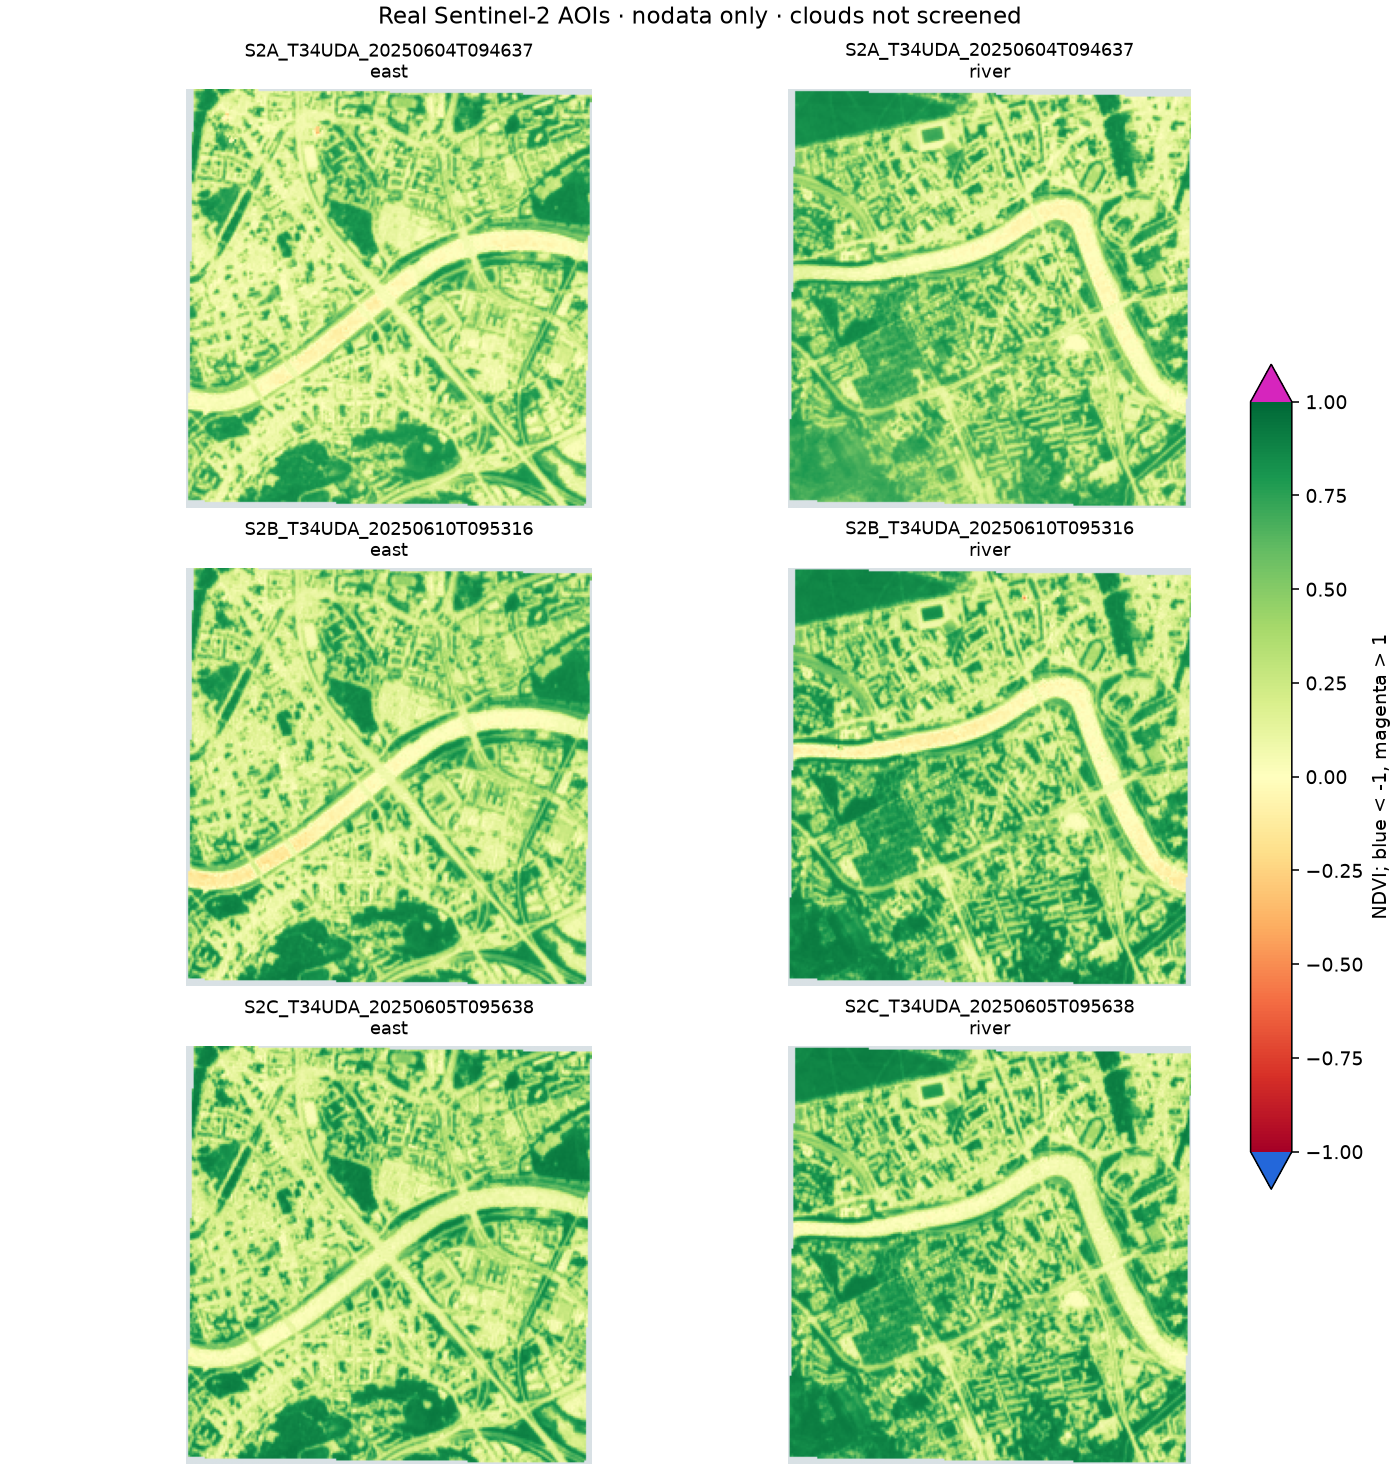

Open: C:\Users\micha\AGH\Automated workflows in satellite image processing\automated-workflows-labs\Labs\Lab05\reports\main\index.html


In [9]:
report_dir = ROOT / 'reports/main'
if not report_dir.exists():
    print(cli('report', '--manifest', MANIFEST, '--output', report_dir))
report = json.loads((report_dir / 'report.json').read_text())
print(report['summary'])
from IPython.display import Image, display
if (report_dir / 'preview.png').is_file():
    display(Image(filename=str(report_dir / 'preview.png')))
print('Open:', report_dir / 'index.html')

If the report says complete, what has it established? Give two reasons that still would not justify calling the image a clear sky vegetation observation. Identify the observation times separately from the report generation time.

Your explanation:

*Write here.*

Complete establishes verified bytes, grid and provenance for all six outputs; no cloud mask or independent vegetation suitability assessment was performed.
Member observed_at and result checked_at describe evidence times, while generated_at describes report export.

## 6. Case A · One input disappears

The case helper creates a separate workspace, moves one red input aside, and runs the normal coordinator. Your main workspace and preserved fixtures stay intact.

Predict the expected member count, attempt count and number of completed requests. Then identify the exact blocked member and input role using SQL.

In [10]:
def ensure_case(name, directory, expected=(0, 1)):
    case_manifest = ROOT / directory / 'batch.json'
    if not case_manifest.exists():
        result = cli('case', '--name', name, '--directory', ROOT / directory, expected=expected)
        print('Created:', name, result.get('manifest', result.get('note')))
    return case_manifest

missing = ensure_case('missing-input', 'cases/missing')
query(missing, """SELECT m.member_id, o.state, o.reason, o.observed_at
FROM batch_members m JOIN batch_observations o USING(batch_id,member_id)
WHERE o.observation_id=(SELECT MAX(x.observation_id) FROM batch_observations x
WHERE x.batch_id=m.batch_id AND x.member_id=m.member_id)
ORDER BY m.member_id""")

Created: missing-input C:\Users\micha\AGH\Automated workflows in satellite image processing\automated-workflows-labs\Labs\Lab05\cases\missing\batch.json


[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-east',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-21T16:22:30.218283Z'},
 {'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'state': 'blocked',
  'reason': 'Missing inputs: red',
  'observed_at': '2026-11-21T16:22:30.211577Z'},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-east',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-21T16:22:30.247385Z'},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-river',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-21T16:22:30.240619Z'},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-east',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-21T16:22:30.233655Z'},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-river',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-21T16:22:30.226005Z'}]

In [11]:
blocked = query(missing, queries[4], {'batch_id': batch_plan.load(missing)['batch_id']})
blocked

[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'role': 'red',
  'local_path': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab05\\cases\\missing\\inputs\\S2A_T34UDA_20250604T094637_L2A-river-red.tif',
  'status': 'missing',
  'reason': 'Missing inputs: red'}]

Explain why the blocked member has no failed application attempt. How does expected membership let us see work that never started? Add the query that established your diagnosis to your query file.

Your explanation:

*Write here.*

The input check blocks the red-band member before launching an application attempt, leaving six expected members, five attempts and five completed results.
Expected membership and the no-attempt query expose the work that never started.

In [12]:
note = json.loads((missing.parent / 'case_note.json').read_text())
if Path(note['held']).exists() and not Path(note['original']).exists():
    print(cli('restore-input', '--manifest', missing))
recovered = cli('run', '--manifest', missing)
print('Complete after restoration:', recovered['complete'])
query(missing, 'SELECT status, COUNT(*) AS n FROM processing_attempts GROUP BY status')

{'status': 'restored', 'path': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab05\\cases\\missing\\inputs\\S2A_T34UDA_20250604T094637_L2A-river-red.tif'}
Complete after restoration: True


[{'status': 'succeeded', 'n': 6}]

## 7. Case B · The worker stops before publication

This helper waits for the actual child process to stop with exit code 86. The child wrote and validated a temporary raster, then exited without running cleanup. Its attempt still says running.

Predict what the coordinator will do with the remaining requests. We still permit only one active processing invocation per catalogue.

In [13]:
worker = ensure_case('interrupted-worker', 'cases/worker')
query(worker, 'SELECT attempt_id, request_id, status, stage, temp_path, final_path FROM processing_attempts ORDER BY started_at')

Created: interrupted-worker C:\Users\micha\AGH\Automated workflows in satellite image processing\automated-workflows-labs\Labs\Lab05\cases\worker\batch.json


[{'attempt_id': 'attempt-0e81a203139b48a69aa1378001c77553',
  'request_id': 'request-da5726b709bba313e36c7be89ee2ae9973e422401d5ebe3011a33a6270b4c6ca',
  'status': 'running',
  'stage': 'before_rename',
  'temp_path': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab05\\cases\\worker\\outputs\\.attempt-0e81a203139b48a69aa1378001c77553.partial.tif',
  'final_path': 'C:\\Users\\micha\\AGH\\Automated workflows in satellite image processing\\automated-workflows-labs\\Labs\\Lab05\\cases\\worker\\outputs\\attempt-0e81a203139b48a69aa1378001c77553.ndvi.tif'}]

Use SQL and file inspection to distinguish an interrupted execution from a missing input. Record why it is justified to assert that this child stopped. In a real unattended system, a timestamp alone would not establish that.

In [14]:
running = query(worker, "SELECT attempt_id, temp_path, final_path FROM processing_attempts WHERE status='running'")
for row in running:
    print(row['attempt_id'], 'temporary:', Path(row['temp_path']).exists(), 'final:', Path(row['final_path']).exists())
print('Output links:', query(worker, 'SELECT COUNT(*) AS n FROM processing_outputs'))

attempt-0e81a203139b48a69aa1378001c77553 temporary: True final: False
Output links: [{'n': 0}]


Your explanation:

*Write here.*

The first worker remains running with a validated temporary file and no published output, so the other five members are blocked.
The adapter waited for exit code 86, establishing that the worker stopped before reconciliation.

In [15]:
for row in running:
    print(cli('reconcile', '--manifest', worker, '--attempt-id', row['attempt_id'], '--confirm-stopped'))
worker_recovered = cli('run', '--manifest', worker)
assert worker_recovered['complete']
query(worker, 'SELECT request_id, status, error_code, started_at FROM processing_attempts ORDER BY started_at')

{'status': 'interrupted', 'attempt_id': 'attempt-0e81a203139b48a69aa1378001c77553', 'retry': 'same request, new attempt'}


[{'request_id': 'request-da5726b709bba313e36c7be89ee2ae9973e422401d5ebe3011a33a6270b4c6ca',
  'status': 'interrupted',
  'error_code': 'PROCESS_STOPPED_BEFORE_PUBLISH',
  'started_at': '2026-11-21T16:22:31.290636Z'},
 {'request_id': 'request-da5726b709bba313e36c7be89ee2ae9973e422401d5ebe3011a33a6270b4c6ca',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-21T16:22:31.858094Z'},
 {'request_id': 'request-d3d51bbba135783565a5a3aa977292043503141c8a07297cbafa155cefaa2251',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-21T16:22:32.277422Z'},
 {'request_id': 'request-cc12f1f1676a33a337f75152cbeb2fcee0c882602b78267cf442952a074b7a7a',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-21T16:22:32.699388Z'},
 {'request_id': 'request-41309888f133072b1d1971b6fe474405475b79948669a7306938b52b40541979',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-21T16:22:33.117714Z'},
 {'request_id': 'request-2a465c4806

Write a query that finds a request with an interrupted or failed attempt and a later producing attempt. Show both identities. Explain why counting attempts would overstate delivered work.

Attempts include interruptions and retries, so distinct verified requests measure delivered work.

In [16]:
from datetime import datetime, timedelta, timezone

recovery = query(worker, queries[1], {'batch_id': batch_plan.load(worker)['batch_id']})
assert recovery
params = {
    'batch_id': batch_plan.load(MANIFEST)['batch_id'],
    'before': (datetime.now(timezone.utc) - timedelta(hours=24)).isoformat().replace('+00:00', 'Z')
}
{
    'recovery': recovery,
    'outputs_without_available_location': query(MANIFEST, queries[2], params),
    'stale_members': query(MANIFEST, queries[3], params)
}

[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'request_id': 'request-da5726b709bba313e36c7be89ee2ae9973e422401d5ebe3011a33a6270b4c6ca',
  'earlier_attempt': 'attempt-0e81a203139b48a69aa1378001c77553',
  'earlier_status': 'interrupted',
  'producing_attempt': 'attempt-9df60d1989eb4ec0998e638b1c83aa6b',
  'artifact_id': 'output-ba632970a9d52d3461274babc209cc5776d8e2be718acac4adec8a242fb4ce40'}]

## 8. A decision another person can follow

It is Saturday morning. One member is blocked because an input file is missing. Five other members have verified outputs. Delivery is required on Monday afternoon.

Write a short note stating what is known, what remains uncertain, the next check, and whether you would act now or defer. Explain how your decision changes if an incorrect calibration may have affected already published products.

Save your useful SQL with a question, parameters, empty-result interpretation and next action. Sketch one overview and one detail view using the fields you actually have. Mark any proposed future measurements as unavailable rather than inventing them.

| View | Fields |
| --- | --- |
| Overview | batch_id, expected, counts, members by state |
| Detail | member_id, request_id, reason, attempt history, location checks, observed_at |
| Unavailable | Cloud suitability and independent calibration validation |

| SQL | Question and parameters | Empty result and next action |
| --- | --- | --- |
| 1 | Members never attempted; batch_id | Every member has an attempt; inspect completion states. |
| 2 | Interrupted/failed requests later verified; batch_id | No recovery pair exists; inspect unresolved attempts. |
| 3 | Succeeded outputs without an available location; batch_id | Each has a recorded available copy; refresh actual file evidence. |
| 4 | Latest observations older than before; batch_id, before = current UTC minus 24 hours | No stale or unobserved members; retain timestamps and refresh before delivery. |
| 5 | Blocked member and missing role; batch_id | No recorded missing input for a blocked member; inspect other blocking reasons. |

Your explanation:

*Write here.*

Five outputs are verified, but the missing input's recoverability is unknown, so I would check its recorded copies and restore it now rather than risk Monday's deadline.
If calibration may be wrong, I would hold affected deliveries, review the interpretation and create corrected scientific requests after confirming the cause.

## Extensions

1. Create `interrupted-coordinator` in a new case directory. The command exits with code 87 after one completed member. Run the same manifest again and prove that only five jobs launch.
2. Create `missing-output`. Inspect both the old succeeded attempt and the new location observations. Recover the output without rewriting history.
3. Add a second copy of a verified output, then remove one copy. Explain why a query using any missing location gives the wrong answer.
4. Repeat the explicit live acquisition command from `README.md` into a new directory. Compare its captured source metadata and subset hashes with the supplied manifest.
5. Change a scientific setting in one configuration and freeze a new manifest. Contrast that new request with a change to an output directory.

Keep extensions separate from your core evidence. Never remove old attempt rows to make a report look clean.

## Submit

Keep your notebook, three table definitions, three repairs, query file, one saved report, and the decision note. Include the failed/interrupted evidence as well as the recovered outcome.

The extensions are optional.